In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [4]:
with open("TeleCom_Data-1.csv", "r", encoding="utf-8") as f:
    lines = f.readlines()

rows = []

for line in lines:
    line = line.strip()

    if line.startswith('"') and line.endswith('"'):
        line = line[1:-1]

    fields = [field.strip('"') for field in line.split(";")]
    rows.append(fields)

df = pd.DataFrame(rows[1:], columns=rows[0])

In [5]:
df.head()

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191,no
1,56,services,married,high.school,no,no,yes,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191,no
2,45,services,married,basic.9y,unknown,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191,no
3,59,admin.,married,professional.course,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191,no
4,41,blue-collar,married,unknown,unknown,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191,no


In [6]:
df.tail()

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
41175,29,unemployed,single,basic.4y,no,yes,no,cellular,nov,fri,...,1,9,1,success,-1.1,94.767,-50.8,1.028,4963.6,no
41176,73,retired,married,professional.course,no,yes,no,cellular,nov,fri,...,1,999,0,nonexistent,-1.1,94.767,-50.8,1.028,4963.6,yes
41177,46,blue-collar,married,professional.course,no,no,no,cellular,nov,fri,...,1,999,0,nonexistent,-1.1,94.767,-50.8,1.028,4963.6,no
41178,56,retired,married,university.degree,no,yes,no,cellular,nov,fri,...,2,999,0,nonexistent,-1.1,94.767,-50.8,1.028,4963.6,no
41179,44,technician,married,professional.course,no,no,no,cellular,nov,fri,...,1,999,0,nonexistent,-1.1,94.767,-50.8,1.028,4963.6,yes


In [7]:
df.shape

(41180, 21)

In [8]:
numeric_cols = [
    "age",
    "duration",
    "campaign",
    "pdays",
    "previous",
    "emp.var.rate",
    "cons.price.idx",
    "cons.conf.idx",
    "euribor3m",
    "nr.employed"
]

for col in numeric_cols:
    df[col] = pd.to_numeric(df[col], errors="coerce")

In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 41180 entries, 0 to 41179
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             41180 non-null  int64  
 1   job             41180 non-null  object 
 2   marital         41180 non-null  object 
 3   education       41180 non-null  object 
 4   default         41180 non-null  object 
 5   housing         41180 non-null  object 
 6   loan            41180 non-null  object 
 7   contact         41180 non-null  object 
 8   month           41180 non-null  object 
 9   day_of_week     41180 non-null  object 
 10  duration        41180 non-null  int64  
 11  campaign        41180 non-null  int64  
 12  pdays           41180 non-null  int64  
 13  previous        41180 non-null  int64  
 14  poutcome        41180 non-null  object 
 15  emp.var.rate    41180 non-null  float64
 16  cons.price.idx  41180 non-null  float64
 17  cons.conf.idx   41180 non-null 

In [10]:
df[numeric_cols].describe()

,age,duration,campaign,pdays,previous,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed
count,41180.000000,41180.000000,41180.000000,41180.000000,41180.000000,41180.000000,41180.000000,41180.000000,41180.000000,41180.000000
mean,40.021710,258.280427,2.567800,962.516707,0.172705,0.081901,93.575508,-40.501999,3.621422,5167.053344
std,10.419593,259.299856,2.770225,186.809028,0.493719,1.571037,0.578762,4.627358,1.734385,72.230334
min,17.000000,0.000000,1.000000,0.000000,0.000000,-3.400000,92.201000,-50.800000,0.634000,4963.600000
25%,32.000000,102.000000,1.000000,999.000000,0.000000,-1.800000,93.075000,-42.700000,1.344000,5099.100000
50%,38.000000,180.000000,2.000000,999.000000,0.000000,1.100000,93.749000,-41.800000,4.857000,5191.000000
75%,47.000000,319.000000,3.000000,999.000000,0.000000,1.400000,93.994000,-36.400000,4.961000,5228.100000
max,98.000000,4918.000000,56.000000,999.000000,7.000000,1.400000,94.767000,-26.900000,5.045000,5228.100000


In [11]:
categorical_cols = [
    "job",
    "marital",
    "education",
    "default",
    "housing",
    "loan",
    "contact",
    "month",
    "day_of_week",
    "poutcome",
    "y"
]

for col in categorical_cols:
    print("\n", "="*40)
    print(col)
    print(df[col].value_counts(dropna=False))


job
job
admin.           10422
blue-collar       9253
technician        6742
services          3967
management        2923
retired           1718
entrepreneur      1456
self-employed     1421
housemaid         1059
unemployed        1014
student            875
unknown            330
Name: count, dtype: int64

marital
marital
married     24921
single      11568
divorced     4611
unknown        80
Name: count, dtype: int64

education
education
university.degree      12166
high.school             9513
basic.9y                6044
professional.course     5241
basic.4y                4175
basic.6y                2292
unknown                 1731
illiterate                18
Name: count, dtype: int64

default
default
no         32581
unknown     8596
yes            3
Name: count, dtype: int64

housing
housing
yes        21571
no         18619
unknown      990
Name: count, dtype: int64

loan
loan
no         33943
yes         6247
unknown      990
Name: count, dtype: int64

contact
contact
ce

In [12]:
housing_unknown = df["housing"] == "unknown"
loan_unknown = df["loan"] == "unknown"

print("Housing unknown:", housing_unknown.sum())
print("Loan unknown:", loan_unknown.sum())
print("Both unknown:", (housing_unknown & loan_unknown).sum())

Housing unknown: 990
Loan unknown: 990
Both unknown: 990


In [13]:
pd.crosstab(df["housing"], df["loan"])

loan,no,unknown,yes
housing,,,
no,16062,0,2557
unknown,0,990,0
yes,17881,0,3690


In [14]:
df.groupby("housing")["y"].value_counts(normalize=True).unstack() * 100

y,no,yes
housing,,
no,89.124013,10.875987
unknown,89.191919,10.808081
yes,88.382551,11.617449


In [15]:
df.groupby("loan")["y"].value_counts(normalize=True).unstack() * 100

y,no,yes
loan,,
no,88.663347,11.336653
unknown,89.191919,10.808081
yes,89.066752,10.933248


In [16]:
df.groupby("default")["y"].value_counts(normalize=True).unstack() * 100

y,no,yes
default,,
no,87.124398,12.875602
unknown,94.846440,5.153560
yes,100.000000,NaN


In [17]:
pd.crosstab(df["default"], df["y"])

y,no,yes
default,,
no,28386,4195
unknown,8153,443
yes,3,0


In [18]:
default_unknown = df["default"] == "unknown"
housing_unknown = df["housing"] == "unknown"

print("Default unknown:", default_unknown.sum())
print("Housing unknown:", housing_unknown.sum())
print("Both unknown:", (default_unknown & housing_unknown).sum())

Default unknown: 8596
Housing unknown: 990
Both unknown: 227


In [19]:
loan_unknown = df["loan"] == "unknown"

print("Default + loan unknown:", (default_unknown & loan_unknown).sum())

Default + loan unknown: 227


In [20]:
unknown_pattern = (
    (df["default"] == "unknown") &
    (df["housing"] == "unknown") &
    (df["loan"] == "unknown")
)

print("All three unknown:", unknown_pattern.sum())

print(
    df.loc[unknown_pattern, "education"]
    .value_counts()
)

All three unknown: 227
education
basic.4y               54
university.degree      39
basic.9y               38
high.school            34
basic.6y               24
professional.course    20
unknown                18
Name: count, dtype: int64


In [21]:
df.loc[unknown_pattern, "y"].value_counts(normalize=True) * 100

,proportion
y,
no,95.154185
yes,4.845815


In [22]:
df.duplicated().sum()

np.int64(12)

In [23]:
df[df.duplicated(keep=False)].sort_values(by=list(df.columns))

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
28472,24,services,single,high.school,no,yes,no,cellular,apr,tue,...,1,999,0,nonexistent,-1.8,93.075,-47.1,1.423,5099.1,no
28473,24,services,single,high.school,no,yes,no,cellular,apr,tue,...,1,999,0,nonexistent,-1.8,93.075,-47.1,1.423,5099.1,no
14151,27,technician,single,professional.course,no,no,no,cellular,jul,mon,...,2,999,0,nonexistent,1.4,93.918,-42.7,4.962,5228.1,no
14230,27,technician,single,professional.course,no,no,no,cellular,jul,mon,...,2,999,0,nonexistent,1.4,93.918,-42.7,4.962,5228.1,no
18460,32,technician,single,professional.course,no,yes,no,cellular,jul,thu,...,1,999,0,nonexistent,1.4,93.918,-42.7,4.968,5228.1,no
18461,32,technician,single,professional.course,no,yes,no,cellular,jul,thu,...,1,999,0,nonexistent,1.4,93.918,-42.7,4.968,5228.1,no
32501,35,admin.,married,university.degree,no,yes,no,cellular,may,fri,...,4,999,0,nonexistent,-1.8,92.893,-46.2,1.313,5099.1,no
32512,35,admin.,married,university.degree,no,yes,no,cellular,may,fri,...,4,999,0,nonexistent,-1.8,92.893,-46.2,1.313,5099.1,no
12256,36,retired,married,unknown,no,no,no,telephone,jul,thu,...,1,999,0,nonexistent,1.4,93.918,-42.7,4.966,5228.1,no
12257,36,retired,married,unknown,no,no,no,telephone,jul,thu,...,1,999,0,nonexistent,1.4,93.918,-42.7,4.966,5228.1,no


In [24]:
print("Original rows:", len(df))
print("Duplicate rows:", df.duplicated().sum())
print("Rows after removing duplicates:", len(df.drop_duplicates()))

Original rows: 41180
Duplicate rows: 12
Rows after removing duplicates: 41168


In [25]:
df_clean = df.drop_duplicates().copy()

In [26]:
print(df_clean.shape)

(41168, 21)


In [27]:
pd.crosstab(df_clean["previous"], df_clean["poutcome"])

poutcome,failure,nonexistent,success
previous,,,
0,0,35547,0
1,3695,0,864
2,434,0,320
3,88,0,128
4,29,0,40
5,3,0,15
6,1,0,3
7,0,0,1


In [28]:
pd.crosstab(df_clean["previous"], df_clean["pdays"])

pdays,0,1,2,3,4,5,6,7,8,9,...,17,18,19,20,21,22,25,26,27,999
previous,,,,,,,,,,,,,,,,,,,,,
0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,35547
1,7,16,42,250,73,28,219,26,9,27,...,2,2,2,0,0,3,0,1,1,3695
2,4,5,12,114,29,11,117,23,6,22,...,3,4,1,0,1,0,1,0,0,349
3,2,3,3,43,14,5,57,8,2,12,...,2,1,0,0,0,0,0,0,0,50
4,1,1,3,19,2,0,16,3,1,3,...,1,0,0,1,0,0,0,0,0,11
5,1,0,1,9,0,2,2,0,0,0,...,0,0,0,0,1,0,0,0,0,2
6,0,0,0,3,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,1
7,0,0,0,1,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [29]:
inconsistent_pdays = (
    (df_clean["previous"] > 0) &
    (df_clean["pdays"] == 999)
)

print("previous > 0 and pdays = 999:", inconsistent_pdays.sum())
print(
    "Percentage of dataset:",
    inconsistent_pdays.mean() * 100
)

previous > 0 and pdays = 999: 4108
Percentage of dataset: 9.978624174115817


In [30]:
pd.crosstab(
    df_clean.loc[inconsistent_pdays, "previous"],
    df_clean.loc[inconsistent_pdays, "poutcome"]
)

poutcome,failure
previous,
1,3695
2,349
3,50
4,11
5,2
6,1


In [31]:
pd.crosstab(
    df_clean["poutcome"],
    df_clean["pdays"] == 999,
    normalize="index"
) * 100

pdays,False,True
poutcome,,
failure,3.341176,96.658824
nonexistent,0.000000,100.000000
success,100.000000,0.000000


In [32]:
pd.crosstab(
    df_clean["poutcome"],
    df_clean["previous"] == 0,
    normalize="index"
) * 100

previous,False,True
poutcome,,
failure,100.0,0.0
nonexistent,0.0,100.0
success,100.0,0.0


In [33]:
print("pdays = 999:", (df_clean["pdays"] == 999).sum())
print("pdays < 999:", (df_clean["pdays"] < 999).sum())

pdays = 999: 39655
pdays < 999: 1513


In [34]:
df_clean.loc[df_clean["pdays"] < 999, "pdays"].describe()

,pdays
count,1513.000000
mean,6.017845
std,3.825260
min,0.000000
25%,3.000000
50%,6.000000
75%,7.000000
max,27.000000


In [35]:
df_clean.loc[df_clean["pdays"] < 999, "pdays"].value_counts().sort_index()

,count
pdays,
0,15
1,25
2,61
3,439
4,118
5,46
6,411
7,60
8,18


In [36]:
print("Age below 18:", (df_clean["age"] < 18).sum())
print("Age above 100:", (df_clean["age"] > 100).sum())
print("Negative duration:", (df_clean["duration"] < 0).sum())
print("Campaign below 1:", (df_clean["campaign"] < 1).sum())
print("Previous below 0:", (df_clean["previous"] < 0).sum())
print("Pdays below -1:", (df_clean["pdays"] < -1).sum())

Age below 18: 5
Age above 100: 0
Negative duration: 0
Campaign below 1: 0
Previous below 0: 0
Pdays below -1: 0


In [37]:
df_clean[df_clean["age"] < 18]

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
37136,17,student,single,unknown,no,yes,no,cellular,aug,wed,...,3,4,2,success,-2.9,92.201,-31.4,0.884,5076.2,no
37535,17,student,single,basic.9y,no,yes,no,cellular,aug,fri,...,2,999,2,failure,-2.9,92.201,-31.4,0.869,5076.2,no
37554,17,student,single,basic.9y,no,yes,no,cellular,aug,fri,...,3,4,2,success,-2.9,92.201,-31.4,0.869,5076.2,no
37575,17,student,single,basic.9y,no,unknown,unknown,cellular,aug,fri,...,2,999,1,failure,-2.9,92.201,-31.4,0.869,5076.2,yes
38270,17,student,single,unknown,no,no,yes,cellular,oct,tue,...,1,2,2,success,-3.4,92.431,-26.9,0.742,5017.5,yes


In [38]:
df_clean[df_clean["age"] < 18]["age"].value_counts().sort_index()

,count
age,
17,5


In [39]:
df_clean["duration"].describe(percentiles=[.01, .05, .25, .5, .75, .95, .99])

,duration
count,41168.000000
mean,258.311237
std,259.325938
min,0.000000
1%,11.000000
5%,36.000000
25%,102.000000
50%,180.000000
75%,319.000000
95%,753.000000


In [40]:
df_clean["campaign"].describe(percentiles=[.01, .05, .25, .5, .75, .95, .99])

,campaign
count,41168.000000
mean,2.568087
std,2.770530
min,1.000000
1%,1.000000
5%,1.000000
25%,1.000000
50%,2.000000
75%,3.000000
95%,7.000000


In [41]:
df_clean["age"].describe(
    percentiles=[.01, .05, .25, .5, .75, .95, .99]
)

,age
count,41168.000000
mean,40.021449
std,10.419022
min,17.000000
1%,23.000000
5%,26.000000
25%,32.000000
50%,38.000000
75%,47.000000
95%,58.000000


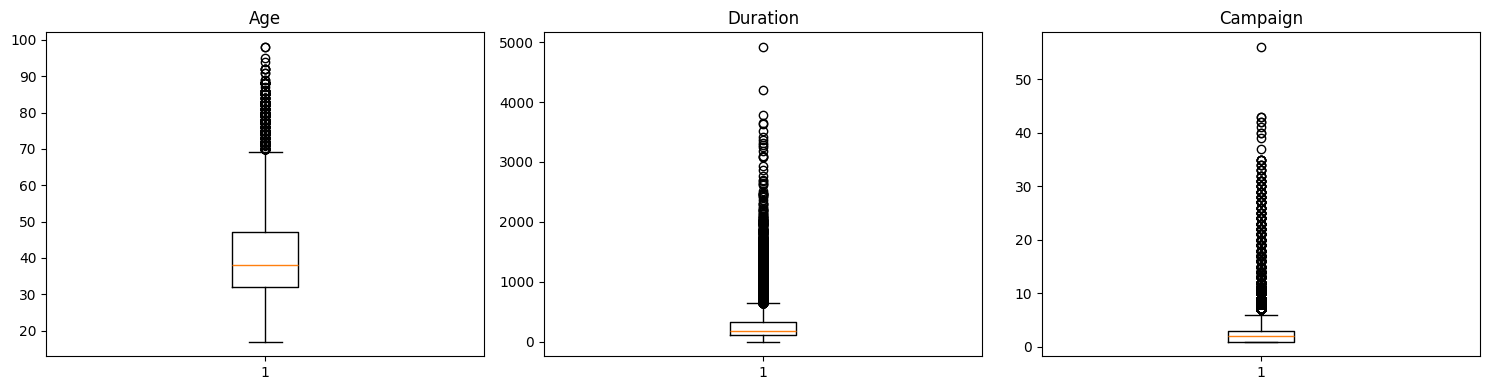

In [42]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

axes[0].boxplot(df_clean["age"])
axes[0].set_title("Age")

axes[1].boxplot(df_clean["duration"])
axes[1].set_title("Duration")

axes[2].boxplot(df_clean["campaign"])
axes[2].set_title("Campaign")

plt.tight_layout()
plt.show()

In [43]:
macro_cols = [
    "emp.var.rate",
    "cons.price.idx",
    "cons.conf.idx",
    "euribor3m",
    "nr.employed"
]

df_clean[macro_cols].describe()

,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed
count,41168.000000,41168.000000,41168.000000,41168.000000,41168.000000
mean,0.081937,93.575563,-40.502261,3.621425,5167.052308
std,1.570960,0.578761,4.627020,1.734375,72.230165
min,-3.400000,92.201000,-50.800000,0.634000,4963.600000
25%,-1.800000,93.075000,-42.700000,1.344000,5099.100000
50%,1.100000,93.749000,-41.800000,4.857000,5191.000000
75%,1.400000,93.994000,-36.400000,4.961000,5228.100000
max,1.400000,94.767000,-26.900000,5.045000,5228.100000


In [44]:
for col in macro_cols:
    print(col, "→", df_clean[col].nunique(), "unique values")

emp.var.rate → 10 unique values
cons.price.idx → 26 unique values
cons.conf.idx → 26 unique values
euribor3m → 316 unique values
nr.employed → 11 unique values


In [45]:
for col in macro_cols:
    print("\n", col)
    print(df_clean[col].value_counts().head(10))


 emp.var.rate
emp.var.rate
 1.4    16228
-1.8     9182
 1.1     7758
-0.1     3682
-2.9     1662
-3.4     1070
-1.7      773
-1.1      631
-3.0      172
-0.2       10
Name: count, dtype: int64

 cons.price.idx
cons.price.idx
93.994    7758
93.918    6681
92.893    5793
93.444    5173
94.465    4374
93.200    3615
93.075    2457
92.201     770
92.963     715
92.431     446
Name: count, dtype: int64

 cons.conf.idx
cons.conf.idx
-36.4    7758
-42.7    6681
-46.2    5793
-36.1    5173
-41.8    4374
-42.0    3615
-47.1    2457
-31.4     770
-40.8     715
-26.9     446
Name: count, dtype: int64

 euribor3m
euribor3m
4.857    2864
4.962    2611
4.963    2487
4.961    1902
4.856    1210
4.964    1175
1.405    1169
4.965    1070
4.864    1044
4.960    1013
Name: count, dtype: int64

 nr.employed
nr.employed
5228.1    16228
5099.1     8532
5191.0     7758
5195.8     3682
5076.2     1662
5017.5     1070
4991.6      773
5008.7      650
4963.6      631
5023.5      172
Name: count, dtype: int64


In [46]:
df_clean[macro_cols].corr()

,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed
emp.var.rate,1.000000,0.775615,0.196103,0.972266,0.907121
cons.price.idx,0.775615,1.000000,0.059583,0.688679,0.522810
cons.conf.idx,0.196103,0.059583,1.000000,0.277594,0.100109
euribor3m,0.972266,0.688679,0.277594,1.000000,0.945209
nr.employed,0.907121,0.522810,0.100109,0.945209,1.000000


In [47]:
print("Shape:", df_clean.shape)
print("Duplicate rows:", df_clean.duplicated().sum())
print("Total missing values:", df_clean.isna().sum().sum())

Shape: (41168, 21)
Duplicate rows: 0
Total missing values: 0


In [48]:
df_clean.dtypes

,0
age,int64
job,object
marital,object
education,object
default,object
housing,object
loan,object
contact,object
month,object
day_of_week,object


In [49]:
df_clean["y"].value_counts(normalize=True) * 100

,proportion
y,
no,88.736397
yes,11.263603


In [50]:
target_rate = df_clean["y"].value_counts(normalize=True) * 100
print(target_rate)

y
no     88.736397
yes    11.263603
Name: proportion, dtype: float64


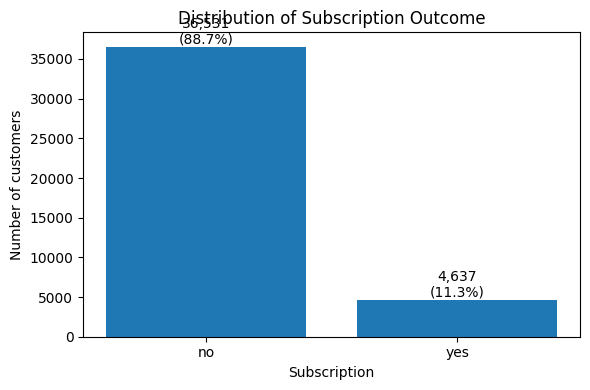

In [51]:
import matplotlib.pyplot as plt

y_counts = df_clean["y"].value_counts()

plt.figure(figsize=(6, 4))
bars = plt.bar(y_counts.index, y_counts.values)

plt.title("Distribution of Subscription Outcome")
plt.xlabel("Subscription")
plt.ylabel("Number of customers")

total = len(df_clean)

for bar, count in zip(bars, y_counts.values):
    percentage = count / total * 100
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{count:,}\n({percentage:.1f}%)",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()

In [52]:
df_clean["age"].value_counts().sort_index()

,count
age,
17,5
18,28
19,42
20,65
21,102
...,...
91,2
92,4
94,1


In [53]:
age_bins = [16, 25, 35, 45, 55, 65, 100]
age_labels = ["17–25", "26–35", "36–45", "46–55", "56–65", "66+"]

age_groups = pd.cut(
    df_clean["age"],
    bins=age_bins,
    labels=age_labels
)

age_groups.value_counts().sort_index()

,count
age,
17–25,1665
26–35,14844
36–45,12836
46–55,8246
56–65,2960
66+,617


In [54]:
age_subscription = pd.crosstab(
    age_groups,
    df_clean["y"],
    normalize="index"
) * 100

age_subscription

y,no,yes
age,,
17–25,79.039039,20.960961
26–35,88.278092,11.721908
36–45,91.500467,8.499533
46–55,91.304875,8.695125
56–65,84.797297,15.202703
66+,52.998379,47.001621


In [55]:
age_counts = pd.crosstab(
    age_groups,
    df_clean["y"]
)

age_counts

y,no,yes
age,,
17–25,1316,349
26–35,13104,1740
36–45,11745,1091
46–55,7529,717
56–65,2510,450
66+,327,290


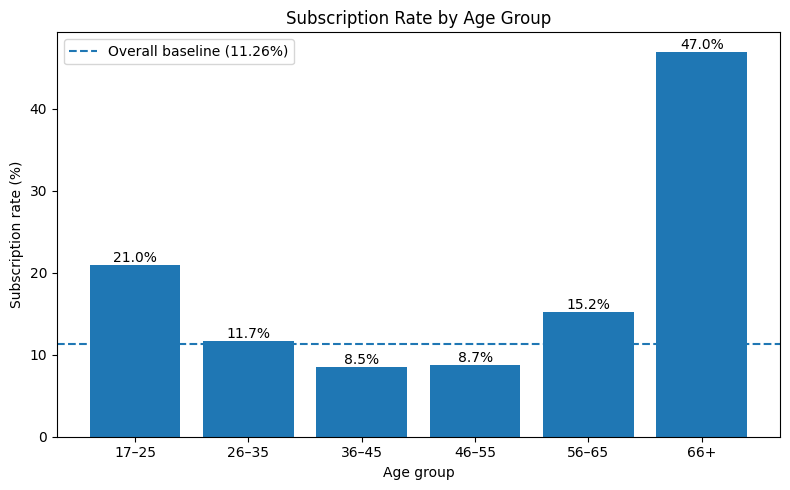

In [56]:
subscription_rates = age_subscription["yes"]
baseline = df_clean["y"].eq("yes").mean() * 100

plt.figure(figsize=(8, 5))

bars = plt.bar(
    subscription_rates.index,
    subscription_rates.values
)

plt.axhline(
    baseline,
    linestyle="--",
    linewidth=1.5,
    label=f"Overall baseline ({baseline:.2f}%)"
)

for bar, rate in zip(bars, subscription_rates.values):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{rate:.1f}%",
        ha="center",
        va="bottom"
    )

plt.title("Subscription Rate by Age Group")
plt.xlabel("Age group")
plt.ylabel("Subscription rate (%)")
plt.legend()

plt.tight_layout()
plt.show()

In [57]:
from scipy.stats import chi2_contingency

age_y_table = pd.crosstab(age_groups, df_clean["y"])

chi2, p_value, dof, expected = chi2_contingency(age_y_table)

print("Chi-square statistic:", chi2)
print("p-value:", p_value)
print("Degrees of freedom:", dof)

Chi-square statistic: 1146.7080309586827
p-value: 1.0248225818245675e-245
Degrees of freedom: 5


In [58]:
n = age_y_table.to_numpy().sum()
cramers_v = np.sqrt(chi2 / (n * min(age_y_table.shape[0] - 1,
                                      age_y_table.shape[1] - 1)))

print("Cramer's V:", cramers_v)

Cramer's V: 0.1668962361692474


In [59]:
job_subscription = pd.crosstab(
    df_clean["job"],
    df_clean["y"],
    normalize="index"
) * 100

job_subscription = job_subscription.sort_values("yes", ascending=False)

job_subscription

y,no,yes
job,,
student,68.571429,31.428571
retired,74.766900,25.233100
unemployed,85.798817,14.201183
admin.,87.033305,12.966695
management,88.778652,11.221348
unknown,88.787879,11.212121
technician,89.180766,10.819234
self-employed,89.514426,10.485574
housemaid,89.990557,10.009443


In [60]:
job_counts = df_clean["job"].value_counts()

job_counts

,count
job,
admin.,10419
blue-collar,9252
technician,6738
services,3965
management,2923
retired,1716
entrepreneur,1456
self-employed,1421
housemaid,1059


In [61]:
job_age = pd.crosstab(
    df_clean["job"],
    age_groups,
    normalize="index"
) * 100

job_age.round(1)

age,17–25,26–35,36–45,46–55,56–65,66+
job,,,,,,
admin.,3.0,44.1,30.5,17.5,4.7,0.1
blue-collar,3.5,33.5,36.3,21.9,4.7,0.1
entrepreneur,1.4,26.2,37.7,26.5,7.9,0.3
housemaid,1.0,17.2,32.4,32.2,14.2,3.0
management,1.3,26.8,35.0,26.8,9.9,0.3
retired,0.1,0.8,2.9,17.3,48.1,30.9
self-employed,2.8,35.4,33.0,21.4,7.2,0.1
services,6.2,40.4,30.5,18.9,4.0,0.0
student,51.9,43.3,4.5,0.3,0.0,0.0


In [62]:
age_job_subscription = pd.crosstab(
    [age_groups, df_clean["job"]],
    df_clean["y"],
    normalize="index"
) * 100

age_job_subscription["yes"].unstack()

job,admin.,blue-collar,entrepreneur,housemaid,management,retired,self-employed,services,student,technician,unemployed,unknown
age,,,,,,,,,,,,
17–25,18.730159,9.174312,5.000000,0.000000,15.789474,0.000000,20.000000,14.285714,36.563877,16.374269,28.571429,75.000000
26–35,14.006090,7.932925,9.162304,7.142857,11.125320,7.692308,11.530815,8.858391,27.176781,12.140132,15.517241,10.000000
36–45,10.211157,5.715987,8.561020,5.830904,11.143695,6.122449,11.300640,7.781457,10.256410,8.978470,10.662824,7.446809
46–55,12.109589,6.512087,6.994819,9.090909,9.195402,8.754209,6.250000,5.882353,66.666667,9.444905,11.453744,3.061224
56–65,19.433198,8.314088,10.434783,17.333333,15.277778,18.666667,10.679612,5.000000,NaN,13.541667,29.629630,16.000000
66+,50.000000,40.000000,50.000000,50.000000,55.555556,46.892655,0.000000,0.000000,NaN,33.333333,33.333333,60.000000


In [63]:
age_job_counts = pd.crosstab(
    age_groups,
    df_clean["job"]
)

age_job_counts

job,admin.,blue-collar,entrepreneur,housemaid,management,retired,self-employed,services,student,technician,unemployed,unknown
age,,,,,,,,,,,,
17–25,315,327,20,11,38,1,40,245,454,171,35,8
26–35,4598,3101,382,182,782,13,503,1603,379,2883,348,70
36–45,3173,3359,549,343,1023,49,469,1208,39,2183,347,94
46–55,1825,2027,386,341,783,297,304,748,3,1207,227,98
56–65,494,433,115,150,288,825,103,160,0,288,54,50
66+,14,5,4,32,9,531,2,1,0,6,3,10


In [64]:
age_job_counts[["student", "retired"]]

job,student,retired
age,,
17–25,454,1
26–35,379,13
36–45,39,49
46–55,3,297
56–65,0,825
66+,0,531


In [65]:
from scipy.stats import chi2_contingency

job_y_table = pd.crosstab(
    df_clean["job"],
    df_clean["y"]
)

chi2_job, p_job, dof_job, expected_job = chi2_contingency(job_y_table)

print("Chi-square statistic:", chi2_job)
print("p-value:", p_job)
print("Degrees of freedom:", dof_job)

Chi-square statistic: 960.0161267578051
p-value: 7.691135758268049e-199
Degrees of freedom: 11


In [66]:
n = job_y_table.to_numpy().sum()

cramers_v_job = np.sqrt(
    chi2_job / (
        n * min(job_y_table.shape[0] - 1,
                job_y_table.shape[1] - 1)
    )
)

print("Cramer's V:", cramers_v_job)

Cramer's V: 0.15270715278977876


In [116]:
age_bins = [16, 25, 35, 45, 55, 65, 100]
age_labels = ["17-25", "26-35", "36-45", "46-55", "56-65", "66+"]

df_clean["age_group"] = pd.cut(
    df["age"],
    bins=age_bins,
    labels=age_labels
)

segment = (
    df_clean.groupby(["age_group", "poutcome"], observed=True)["y"]
      .agg(["count", lambda x: (x == "yes").mean() * 100])
      .reset_index()
      .rename(columns={"<lambda_0>": "subscription_rate"})
)

segment = segment[segment["count"] >= 100]

segment = segment.sort_values("subscription_rate", ascending=False)

print(segment)

   age_group     poutcome  count  subscription_rate
17       66+      success    119          76.470588
14     56-65      success    162          71.604938
2      17-25      success    121          66.942149
8      36-45      success    285          64.210526
5      26-35      success    482          61.825726
11     46-55      success    202          60.891089
16       66+  nonexistent    351          42.735043
15       66+      failure    147          33.333333
0      17-25      failure    220          26.363636
12     56-65      failure    283          24.381625
1      17-25  nonexistent   1324          15.861027
9      46-55      failure    749          12.283044
3      26-35      failure   1624          12.253695
6      36-45      failure   1227          11.246944
13     56-65  nonexistent   2515          10.536779
4      26-35  nonexistent  12738           9.758204
10     46-55  nonexistent   7295           6.881426
7      36-45  nonexistent  11324           6.799717


In [67]:
education_subscription = pd.crosstab(
    df_clean["education"],
    df_clean["y"],
    normalize="index"
) * 100

education_subscription = education_subscription.sort_values(
    "yes",
    ascending=False
)

education_subscription

y,no,yes
education,,
illiterate,77.777778,22.222222
unknown,85.491329,14.508671
university.degree,86.285150,13.714850
professional.course,88.659794,11.340206
high.school,89.158780,10.841220
basic.4y,89.748503,10.251497
basic.6y,91.793976,8.206024
basic.9y,92.174057,7.825943


In [68]:
education_counts = df_clean["education"].value_counts()
education_counts

,count
education,
university.degree,12162
high.school,9510
basic.9y,6044
professional.course,5238
basic.4y,4175
basic.6y,2291
unknown,1730
illiterate,18


In [69]:
education_y_table = pd.crosstab(
    df_clean["education"],
    df_clean["y"]
)

chi2_education, p_education, dof_education, expected_education = chi2_contingency(
    education_y_table
)

print("Chi-square statistic:", chi2_education)
print("p-value:", p_education)
print("Degrees of freedom:", dof_education)

Chi-square statistic: 192.40106144950568
p-value: 4.659316429321491e-38
Degrees of freedom: 7


In [70]:
n = education_y_table.to_numpy().sum()

cramers_v_education = np.sqrt(
    chi2_education / (
        n * min(
            education_y_table.shape[0] - 1,
            education_y_table.shape[1] - 1
        )
    )
)

print("Cramer's V:", cramers_v_education)

Cramer's V: 0.06836343046106606


In [71]:
financial_vars = ["default", "housing", "loan"]

for var in financial_vars:
    print(f"\n{'='*40}")
    print(var.upper())

    table = pd.crosstab(
        df_clean[var],
        df_clean["y"],
        normalize="index"
    ) * 100

    print(table.round(2))


DEFAULT
y            no    yes
default               
no        87.12  12.88
unknown   94.85   5.15
yes      100.00   0.00

HOUSING
y           no    yes
housing              
no       89.13  10.87
unknown  89.19  10.81
yes      88.38  11.62

LOAN
y           no    yes
loan                 
no       88.66  11.34
unknown  89.19  10.81
yes      89.07  10.93


In [72]:
for var in financial_vars:
    print(f"\n{var}")
    print(df_clean[var].value_counts())


default
default
no         32570
unknown     8595
yes            3
Name: count, dtype: int64

housing
housing
yes        21566
no         18612
unknown      990
Name: count, dtype: int64

loan
loan
no         33931
yes         6247
unknown      990
Name: count, dtype: int64


In [73]:
default_y_table = pd.crosstab(
    df_clean["default"],
    df_clean["y"]
)

chi2_default, p_default, dof_default, expected_default = chi2_contingency(
    default_y_table
)

print("Chi-square statistic:", chi2_default)
print("p-value:", p_default)
print("Degrees of freedom:", dof_default)

Chi-square statistic: 406.1668754932802
p-value: 6.338458054692336e-89
Degrees of freedom: 2


In [74]:
n = default_y_table.to_numpy().sum()

cramers_v_default = np.sqrt(
    chi2_default / (
        n * min(
            default_y_table.shape[0] - 1,
            default_y_table.shape[1] - 1
        )
    )
)

print("Cramer's V:", cramers_v_default)

Cramer's V: 0.09932815454150484


In [75]:
print(expected_default)

[[2.89014446e+04 3.66855543e+03]
 [7.62689334e+03 9.68106661e+02]
 [2.66209192e+00 3.37908084e-01]]


In [76]:
poutcome_subscription = pd.crosstab(
    df_clean["poutcome"],
    df_clean["y"],
    normalize="index"
) * 100

poutcome_subscription = poutcome_subscription.sort_values(
    "yes",
    ascending=False
)

poutcome_subscription

y,no,yes
poutcome,,
success,34.938001,65.061999
failure,85.764706,14.235294
nonexistent,91.166624,8.833376


In [77]:
poutcome_counts = df_clean["poutcome"].value_counts()

poutcome_counts

,count
poutcome,
nonexistent,35547
failure,4250
success,1371


In [78]:
poutcome_y_table = pd.crosstab(
    df_clean["poutcome"],
    df_clean["y"]
)

chi2_poutcome, p_poutcome, dof_poutcome, expected_poutcome = chi2_contingency(
    poutcome_y_table
)

print("Chi-square statistic:", chi2_poutcome)
print("p-value:", p_poutcome)
print("Degrees of freedom:", dof_poutcome)

Chi-square statistic: 4217.65740769466
p-value: 0.0
Degrees of freedom: 2


In [79]:
n = poutcome_y_table.to_numpy().sum()

cramers_v_poutcome = np.sqrt(
    chi2_poutcome / (
        n * min(
            poutcome_y_table.shape[0] - 1,
            poutcome_y_table.shape[1] - 1
        )
    )
)

print("Cramer's V:", cramers_v_poutcome)

Cramer's V: 0.3200779563886298


In [80]:
previous_positive = df_clean[df_clean["previous"] > 0]

previous_subscription = pd.crosstab(
    previous_positive["previous"],
    previous_positive["y"],
    normalize="index"
) * 100

previous_subscription.round(2)

y,no,yes
previous,,
1,78.81,21.19
2,53.58,46.42
3,40.74,59.26
4,44.93,55.07
5,27.78,72.22
6,50.00,50.00
7,100.00,0.00


In [81]:
previous_counts = previous_positive["previous"].value_counts().sort_index()

previous_counts

,count
previous,
1,4559
2,754
3,216
4,69
5,18
6,4
7,1


In [82]:
previous_poutcome = pd.crosstab(
    df_clean["previous"],
    df_clean["poutcome"]
)

previous_poutcome

poutcome,failure,nonexistent,success
previous,,,
0,0,35547,0
1,3695,0,864
2,434,0,320
3,88,0,128
4,29,0,40
5,3,0,15
6,1,0,3
7,0,0,1


In [83]:
previous_poutcome_y = pd.crosstab(
    [df_clean["poutcome"], df_clean["previous"]],
    df_clean["y"],
    normalize="index"
) * 100

previous_poutcome_y["yes"].unstack()

previous,0,1,2,3,4,5,6,7
poutcome,,,,,,,,
failure,NaN,12.205683,25.806452,36.363636,31.034483,33.333333,0.000000,NaN
nonexistent,8.833376,NaN,NaN,NaN,NaN,NaN,NaN,NaN
success,NaN,59.606481,74.375000,75.000000,72.500000,80.000000,66.666667,0.0


In [84]:
duration_bins = [0, 30, 120, 300, 600, np.inf]

duration_labels = [
    "<30 sec",
    "30–120 sec",
    "120–300 sec",
    "300–600 sec",
    ">600 sec"
]

duration_groups = pd.cut(
    df_clean["duration"],
    bins=duration_bins,
    labels=duration_labels,
    include_lowest=True
)

In [85]:
duration_counts = duration_groups.value_counts().sort_index()

duration_counts

,count
duration,
<30 sec,1724
30–120 sec,11188
120–300 sec,17056
300–600 sec,7736
>600 sec,3464


In [86]:
duration_subscription = pd.crosstab(
    duration_groups,
    df_clean["y"],
    normalize="index"
) * 100

duration_subscription.round(2)

y,no,yes
duration,,
<30 sec,100.00,0.00
30–120 sec,98.52,1.48
120–300 sec,92.08,7.92
300–600 sec,81.42,18.58
>600 sec,51.39,48.61


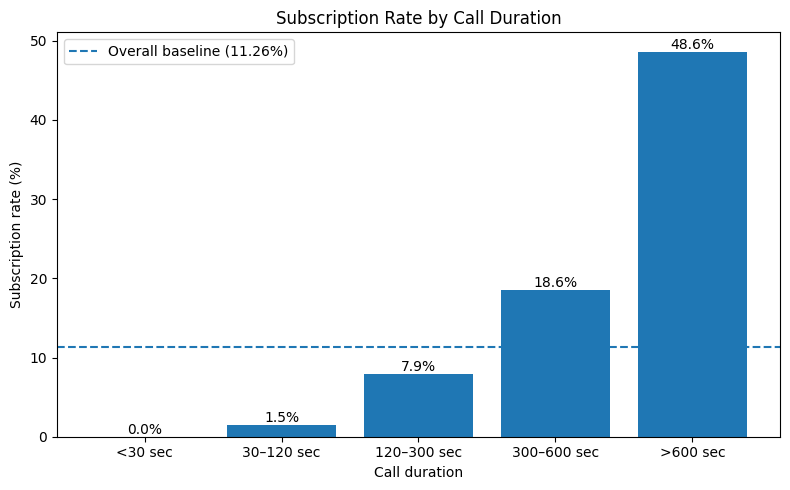

In [87]:
duration_subscription_rate = duration_subscription["yes"]

baseline = df_clean["y"].eq("yes").mean() * 100

plt.figure(figsize=(8, 5))

bars = plt.bar(
    duration_subscription_rate.index,
    duration_subscription_rate.values
)

plt.axhline(
    baseline,
    linestyle="--",
    linewidth=1.5,
    label=f"Overall baseline ({baseline:.2f}%)"
)

for bar, rate in zip(
    bars,
    duration_subscription_rate.values
):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{rate:.1f}%",
        ha="center",
        va="bottom"
    )

plt.title("Subscription Rate by Call Duration")
plt.xlabel("Call duration")
plt.ylabel("Subscription rate (%)")
plt.legend()

plt.tight_layout()
plt.show()

In [88]:
duration_y_table = pd.crosstab(
    duration_groups,
    df_clean["y"]
)

chi2_duration, p_duration, dof_duration, expected_duration = chi2_contingency(
    duration_y_table
)

print("Chi-square statistic:", chi2_duration)
print("p-value:", p_duration)
print("Degrees of freedom:", dof_duration)

Chi-square statistic: 6729.607421922737
p-value: 0.0
Degrees of freedom: 4


In [89]:
n = duration_y_table.to_numpy().sum()

cramers_v_duration = np.sqrt(
    chi2_duration / (
        n * min(
            duration_y_table.shape[0] - 1,
            duration_y_table.shape[1] - 1
        )
    )
)

print("Cramer's V:", cramers_v_duration)

Cramer's V: 0.4043104631231012


In [90]:
df_clean["campaign"].value_counts().sort_index()

,count
campaign,
1,17629
2,10566
3,5339
4,2650
5,1599
6,979
7,629
8,400
9,283


In [91]:
campaign_bins = [0, 1, 2, 3, 5, 10, np.inf]

campaign_labels = [
    "1 contact",
    "2 contacts",
    "3 contacts",
    "4–5 contacts",
    "6–10 contacts",
    ">10 contacts"
]

campaign_groups = pd.cut(
    df_clean["campaign"],
    bins=campaign_bins,
    labels=campaign_labels,
    include_lowest=True
)

In [92]:
campaign_counts = campaign_groups.value_counts().sort_index()

campaign_counts

,count
campaign,
1 contact,17629
2 contacts,10566
3 contacts,5339
4–5 contacts,4249
6–10 contacts,2516
>10 contacts,869


In [93]:
campaign_subscription = pd.crosstab(
    campaign_groups,
    df_clean["y"],
    normalize="index"
) * 100

campaign_subscription.round(2)

y,no,yes
campaign,,
1 contact,86.96,13.04
2 contacts,88.55,11.45
3 contacts,89.25,10.75
4–5 contacts,91.32,8.68
6–10 contacts,93.68,6.32
>10 contacts,96.89,3.11


In [94]:
campaign_y_table = pd.crosstab(
    campaign_groups,
    df_clean["y"]
)

chi2_campaign, p_campaign, dof_campaign, expected_campaign = chi2_contingency(
    campaign_y_table
)

print("Chi-square statistic:", chi2_campaign)
print("p-value:", p_campaign)
print("Degrees of freedom:", dof_campaign)

Chi-square statistic: 204.79947133958436
p-value: 2.6700412899923446e-42
Degrees of freedom: 5


In [95]:
n = campaign_y_table.to_numpy().sum()

cramers_v_campaign = np.sqrt(
    chi2_campaign / (
        n * min(
            campaign_y_table.shape[0] - 1,
            campaign_y_table.shape[1] - 1
        )
    )
)

print("Cramer's V:", cramers_v_campaign)

Cramer's V: 0.07053172916341409


In [96]:
contact_subscription = pd.crosstab(
    df_clean["contact"],
    df_clean["y"],
    normalize="index"
) * 100

contact_subscription.round(2)

y,no,yes
contact,,
cellular,85.27,14.73
telephone,94.77,5.23


In [97]:
contact_y_table = pd.crosstab(
    df_clean["contact"],
    df_clean["y"]
)

chi2_contact, p_contact, dof_contact, expected_contact = chi2_contingency(
    contact_y_table
)

print("Chi-square statistic:", chi2_contact)
print("p-value:", p_contact)
print("Degrees of freedom:", dof_contact)

Chi-square statistic: 860.8334981810171
p-value: 3.2089162729521324e-189
Degrees of freedom: 1


In [98]:
n = contact_y_table.to_numpy().sum()

cramers_v_contact = np.sqrt(
    chi2_contact / (
        n * min(
            contact_y_table.shape[0] - 1,
            contact_y_table.shape[1] - 1
        )
    )
)

print("Cramer's V:", cramers_v_contact)

Cramer's V: 0.14460379636499485


In [99]:
df_clean["contact"].value_counts()

,count
contact,
cellular,26131
telephone,15037


In [100]:
month_subscription = pd.crosstab(
    df_clean["month"],
    df_clean["y"],
    normalize="index"
) * 100

month_subscription.sort_values(
    "yes",
    ascending=False
).round(2)

y,no,yes
month,,
mar,49.45,50.55
dec,51.10,48.90
sep,55.09,44.91
oct,56.07,43.93
apr,79.51,20.49
aug,89.39,10.61
jun,89.49,10.51
nov,89.89,10.11
jul,90.96,9.04


In [101]:
month_y_table = pd.crosstab(
    df_clean["month"],
    df_clean["y"]
)

chi2_month, p_month, dof_month, expected_month = chi2_contingency(
    month_y_table
)

print("Chi-square statistic:", chi2_month)
print("p-value:", p_month)
print("Degrees of freedom:", dof_month)

Chi-square statistic: 3103.6905347599236
p-value: 0.0
Degrees of freedom: 9


In [102]:
n = month_y_table.to_numpy().sum()

cramers_v_month = np.sqrt(
    chi2_month / (
        n * min(
            month_y_table.shape[0] - 1,
            month_y_table.shape[1] - 1
        )
    )
)

print("Cramer's V:", cramers_v_month)

Cramer's V: 0.2745739436534759


In [103]:
month_summary = pd.DataFrame({
    "n": df_clean["month"].value_counts(),
    "subscription_rate": df_clean.groupby("month")["y"].apply(
        lambda x: (x == "yes").mean() * 100
    )
}).sort_values("subscription_rate", ascending=False)

month_summary.round(2)

,n,subscription_rate
month,,
mar,546,50.55
dec,182,48.90
sep,570,44.91
oct,717,43.93
apr,2631,20.49
aug,6176,10.61
jun,5318,10.51
nov,4096,10.11
jul,7169,9.04


In [104]:
day_subscription = pd.crosstab(
    df_clean["day_of_week"],
    df_clean["y"],
    normalize="index"
) * 100

day_subscription.round(2)

y,no,yes
day_of_week,,
fri,89.19,10.81
mon,90.06,9.94
thu,87.90,12.10
tue,88.21,11.79
wed,88.33,11.67


In [105]:
day_y_table = pd.crosstab(
    df_clean["day_of_week"],
    df_clean["y"]
)

chi2_day, p_day, dof_day, expected_day = chi2_contingency(
    day_y_table
)

print("Chi-square statistic:", chi2_day)
print("p-value:", p_day)
print("Degrees of freedom:", dof_day)

Chi-square statistic: 26.033472341587366
p-value: 3.115661068005872e-05
Degrees of freedom: 4


In [106]:
n = day_y_table.to_numpy().sum()

cramers_v_day = np.sqrt(
    chi2_day / (
        n * min(
            day_y_table.shape[0] - 1,
            day_y_table.shape[1] - 1
        )
    )
)

print("Cramer's V:", cramers_v_day)

Cramer's V: 0.025146999006171792


In [107]:
macro_vars = [
    "emp.var.rate",
    "cons.price.idx",
    "cons.conf.idx",
    "euribor3m",
    "nr.employed"
]

macro_summary = df_clean.groupby("y")[macro_vars].mean().T

macro_summary

y,no,yes
emp.var.rate,0.248865,-1.233146
cons.price.idx,93.603691,93.353968
cons.conf.idx,-40.593132,-39.786370
euribor3m,3.811519,2.123831
nr.employed,5176.175703,5095.176795


In [108]:
macro_median = df_clean.groupby("y")[macro_vars].median().T

macro_median

y,no,yes
emp.var.rate,1.100,-1.800
cons.price.idx,93.918,93.200
cons.conf.idx,-41.800,-40.400
euribor3m,4.857,1.266
nr.employed,5195.800,5099.100


In [109]:
df_clean["y"].value_counts()

,count
y,
no,36531
yes,4637


In [110]:
df_model = df_clean.copy()

df_model["y_binary"] = (
    df_model["y"] == "yes"
).astype(int)

df_model["y_binary"].value_counts()

,count
y_binary,
0,36531
1,4637


ADDITIONAL GRAPHICS AND OTHER VISUALIZATIONS FOR WRITTEN REPORT

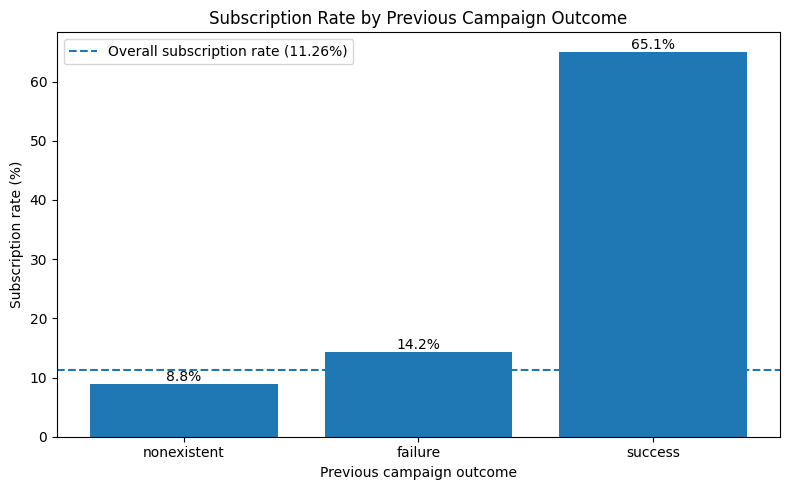

In [111]:
# Calculate subscription rate by previous campaign outcome
poutcome_subscription = pd.crosstab(
    df_clean["poutcome"],
    df_clean["y"],
    normalize="index"
) * 100

poutcome_subscription = poutcome_subscription.reindex(
    ["nonexistent", "failure", "success"]
)

# Overall subscription rate
baseline = (df_clean["y"] == "yes").mean() * 100

# Plot
plt.figure(figsize=(8, 5))

bars = plt.bar(
    poutcome_subscription.index,
    poutcome_subscription["yes"]
)

plt.axhline(
    baseline,
    linestyle="--",
    linewidth=1.5,
    label=f"Overall subscription rate ({baseline:.2f}%)"
)

# Add percentage labels
for bar, rate in zip(
    bars,
    poutcome_subscription["yes"]
):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{rate:.1f}%",
        ha="center",
        va="bottom"
    )

plt.title("Subscription Rate by Previous Campaign Outcome")
plt.xlabel("Previous campaign outcome")
plt.ylabel("Subscription rate (%)")
plt.legend()

plt.tight_layout()
plt.show()

In [112]:
duration_summary = pd.DataFrame({
    "n": duration_groups.value_counts().sort_index(),
    "subscription_rate": duration_subscription["yes"]
})

duration_summary.round(2)

,n,subscription_rate
duration,,
<30 sec,1724,0.00
30–120 sec,11188,1.48
120–300 sec,17056,7.92
300–600 sec,7736,18.58
>600 sec,3464,48.61


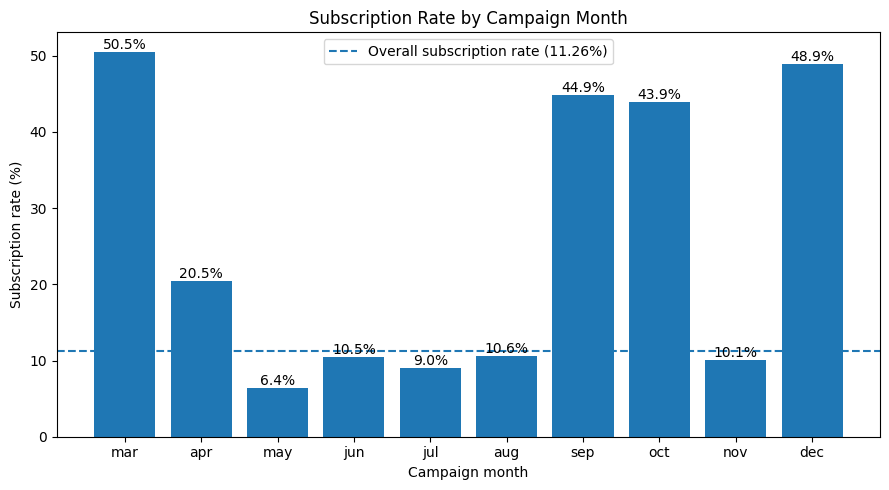

In [113]:
month_subscription = pd.crosstab(
    df_clean["month"],
    df_clean["y"],
    normalize="index"
) * 100

month_order = [
    "mar", "apr", "may", "jun", "jul",
    "aug", "sep", "oct", "nov", "dec"
]

month_subscription = month_subscription.reindex(month_order)

baseline = (df_clean["y"] == "yes").mean() * 100

plt.figure(figsize=(9, 5))

bars = plt.bar(
    month_subscription.index,
    month_subscription["yes"]
)

plt.axhline(
    baseline,
    linestyle="--",
    linewidth=1.5,
    label=f"Overall subscription rate ({baseline:.2f}%)"
)

# Add percentage labels
for bar, rate in zip(
    bars,
    month_subscription["yes"]
):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{rate:.1f}%",
        ha="center",
        va="bottom"
    )

plt.title("Subscription Rate by Campaign Month")
plt.xlabel("Campaign month")
plt.ylabel("Subscription rate (%)")
plt.legend()

plt.tight_layout()
plt.show()